<a href="https://colab.research.google.com/github/sarabaranes-dev/ml-classifier-comparison/blob/main/mnist_rework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from sklearn.datasets import fetch_openml
import numpy as np

# Scarica MNIST: 70.000 cifre scritte a mano, ognuna è un'immagine 28x28 = 784 pixel
mnist = fetch_openml("mnist_784", version=1, as_frame=False)

X_all = mnist.data / 255.0          # pixel da 0-255 a 0-1
y_all = mnist.target.astype(int)    # le etichette: che cifra è (0-9)

# Le ultime 10.000 immagini sono il "test set" ufficiale di MNIST
X_digits = X_all[60000:]
y_digits = y_all[60000:]

print(X_digits.shape)
print(np.bincount(y_digits))

(10000, 784)
[ 980 1135 1032 1010  982  892  958 1028  974 1009]


In [3]:
# Problema a 2 classi: il 5 contro 9, 8 e 0
mask = np.isin(y_digits, [5, 9, 8, 0])     # tiene solo 4 cifre
X = X_digits[mask]
y = (y_digits[mask] == 5).astype(int)      # 1 = è un 5,  0 = è un 9, 8 o 0

print(X.shape)
print(np.bincount(y))

(3855, 784)
[2963  892]


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# 70% delle immagini per addestrare, 30% tenute da parte per la verifica
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=0)

knn = KNeighborsClassifier(n_neighbors=7)   # k-NN con k=7
knn.fit(X_train, y_train)                   # "addestramento"

y_pred = knn.predict(X_test)                # risposta sì/no sulle immagini mai viste
y_score = knn.predict_proba(X_test)[:, 1]   # quanto è "sicuro" che sia un 5

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("F1:      ", round(f1_score(y_test, y_pred), 3))
print("ROC AUC: ", round(roc_auc_score(y_test, y_score), 3))

Accuracy: 0.985
F1:       0.969
ROC AUC:  0.998


In [5]:
from sklearn.model_selection import StratifiedShuffleSplit, GridSearchCV
import pandas as pd

def valuta_modello(nome, modello, parametri, n_split=10):
    # 10 divisioni train/test diverse, sempre le stesse per tutti i modelli
    divisioni = StratifiedShuffleSplit(n_splits=n_split, test_size=0.3, random_state=42)
    risultati = []
    for idx_train, idx_test in divisioni.split(X, y):
        X_tr, X_te = X[idx_train], X[idx_test]
        y_tr, y_te = y[idx_train], y[idx_test]

        # Scelta degli iperparametri SOLO sul train, con validazione incrociata a 5 pezzi
        ricerca = GridSearchCV(modello, parametri, cv=5, scoring="f1", n_jobs=-1)
        ricerca.fit(X_tr, y_tr)
        migliore = ricerca.best_estimator_

        # Una sola misura sul test, mai visto prima
        y_pred = migliore.predict(X_te)
        if hasattr(migliore, "predict_proba"):
            y_score = migliore.predict_proba(X_te)[:, 1]
        else:
            y_score = migliore.decision_function(X_te)

        risultati.append({
            "modello": nome,
            "accuracy": accuracy_score(y_te, y_pred),
            "f1": f1_score(y_te, y_pred),
            "roc_auc": roc_auc_score(y_te, y_score),
            "parametri": str(ricerca.best_params_),
        })

    df = pd.DataFrame(risultati)
    print(nome)
    for m in ["accuracy", "f1", "roc_auc"]:
        print(f"  {m:9}: {df[m].mean():.3f} ± {df[m].std():.3f}")
    print("  parametri scelti:", df["parametri"].value_counts().to_dict())
    return df

In [6]:
risultati_knn = valuta_modello(
    "k-NN",
    KNeighborsClassifier(),
    {"n_neighbors": [1, 3, 5, 7, 9, 11], "weights": ["uniform", "distance"]},
)

k-NN
  accuracy : 0.986 ± 0.003
  f1       : 0.970 ± 0.006
  roc_auc  : 0.995 ± 0.001
  parametri scelti: {"{'n_neighbors': 3, 'weights': 'uniform'}": 5, "{'n_neighbors': 5, 'weights': 'uniform'}": 4, "{'n_neighbors': 7, 'weights': 'uniform'}": 1}


In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron, SGDClassifier, LogisticRegression

risultati_perceptron = valuta_modello(
    "Perceptron",
    make_pipeline(StandardScaler(), Perceptron(random_state=0)),
    {"perceptron__alpha": [1e-4, 1e-3, 1e-2],
     "perceptron__penalty": [None, "l2", "l1"]},
)

risultati_sgd = valuta_modello(
    "SGD",
    make_pipeline(StandardScaler(), SGDClassifier(random_state=0)),
    {"sgdclassifier__loss": ["hinge", "log_loss"],
     "sgdclassifier__alpha": [1e-4, 1e-3, 1e-2, 1e-1]},
)

risultati_logreg = valuta_modello(
    "Logistic Regression",
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    {"logisticregression__C": [0.001, 0.01, 0.1, 1]},
)

Perceptron
  accuracy : 0.941 ± 0.007
  f1       : 0.876 ± 0.014
  roc_auc  : 0.964 ± 0.005
  parametri scelti: {"{'perceptron__alpha': 0.001, 'perceptron__penalty': 'l1'}": 7, "{'perceptron__alpha': 0.0001, 'perceptron__penalty': 'l1'}": 1, "{'perceptron__alpha': 0.0001, 'perceptron__penalty': None}": 1, "{'perceptron__alpha': 0.0001, 'perceptron__penalty': 'l2'}": 1}
SGD
  accuracy : 0.934 ± 0.006
  f1       : 0.845 ± 0.016
  roc_auc  : 0.973 ± 0.006
  parametri scelti: {"{'sgdclassifier__alpha': 0.1, 'sgdclassifier__loss': 'hinge'}": 6, "{'sgdclassifier__alpha': 0.0001, 'sgdclassifier__loss': 'hinge'}": 2, "{'sgdclassifier__alpha': 0.0001, 'sgdclassifier__loss': 'log_loss'}": 2}
Logistic Regression
  accuracy : 0.957 ± 0.004
  f1       : 0.907 ± 0.009
  roc_auc  : 0.981 ± 0.004
  parametri scelti: {"{'logisticregression__C': 0.1}": 8, "{'logisticregression__C': 0.01}": 2}


In [8]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier

# SGD di nuovo, con la griglia allargata verso l'alto --> Il tuning ha scelto 6 volte su 10 alpha = 0.1,
# valore più alto che gli avevo dato. Quando il migliore sta sul bordo della griglia, forse il valore giusto è oltre, quindi ne provo altri
risultati_sgd = valuta_modello(
    "SGD",
    make_pipeline(StandardScaler(), SGDClassifier(random_state=0)),
    {"sgdclassifier__loss": ["hinge", "log_loss"],
     "sgdclassifier__alpha": [1e-3, 1e-2, 1e-1, 1]},
)

risultati_lda = valuta_modello(
    "LDA",
    LinearDiscriminantAnalysis(solver="lsqr"),
    {"shrinkage": ["auto", 0.1, 0.5, 0.9]},
)

risultati_qda = valuta_modello(
    "QDA",
    make_pipeline(PCA(random_state=0), QuadraticDiscriminantAnalysis()),
    {"pca__n_components": [20, 50],
     "quadraticdiscriminantanalysis__reg_param": [0.01, 0.1, 0.5]},
)

risultati_mlp = valuta_modello(
    "MLP",
    make_pipeline(StandardScaler(),
                  MLPClassifier(max_iter=300, early_stopping=True, random_state=0)),
    {"mlpclassifier__hidden_layer_sizes": [(50,), (100,)],
     "mlpclassifier__alpha": [1e-3, 1e-1, 1]},
)

SGD
  accuracy : 0.940 ± 0.006
  f1       : 0.857 ± 0.016
  roc_auc  : 0.973 ± 0.006
  parametri scelti: {"{'sgdclassifier__alpha': 1, 'sgdclassifier__loss': 'hinge'}": 9, "{'sgdclassifier__alpha': 0.1, 'sgdclassifier__loss': 'hinge'}": 1}
LDA
  accuracy : 0.945 ± 0.004
  f1       : 0.884 ± 0.009
  roc_auc  : 0.975 ± 0.004
  parametri scelti: {"{'shrinkage': 0.1}": 5, "{'shrinkage': 0.5}": 5}
QDA
  accuracy : 0.988 ± 0.002
  f1       : 0.975 ± 0.005
  roc_auc  : 0.999 ± 0.000
  parametri scelti: {"{'pca__n_components': 50, 'quadraticdiscriminantanalysis__reg_param': 0.1}": 9, "{'pca__n_components': 50, 'quadraticdiscriminantanalysis__reg_param': 0.01}": 1}
MLP
  accuracy : 0.980 ± 0.003
  f1       : 0.957 ± 0.007
  roc_auc  : 0.995 ± 0.003
  parametri scelti: {"{'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (100,)}": 6, "{'mlpclassifier__alpha': 0.1, 'mlpclassifier__hidden_layer_sizes': (100,)}": 2, "{'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (50

In [9]:
# SGD: prima il migliore era alpha=1 (il massimo) -> provo 10
risultati_sgd = valuta_modello(
    "SGD",
    make_pipeline(StandardScaler(), SGDClassifier(random_state=0)),
    {"sgdclassifier__loss": ["hinge", "log_loss"],
     "sgdclassifier__alpha": [0.1, 1, 10]},
)

# QDA: prima il migliore era 50 componenti (il massimo) -> provo 100 e 150
risultati_qda = valuta_modello(
    "QDA",
    make_pipeline(PCA(random_state=0), QuadraticDiscriminantAnalysis()),
    {"pca__n_components": [50, 100, 150],
     "quadraticdiscriminantanalysis__reg_param": [0.01, 0.1, 0.5]},
)

# MLP: prima il migliore era alpha=1 e 100 neuroni (i massimi) -> provo alpha=10 e 200 neuroni
risultati_mlp = valuta_modello(
    "MLP",
    make_pipeline(StandardScaler(),
                  MLPClassifier(max_iter=300, early_stopping=True, random_state=0)),
    {"mlpclassifier__hidden_layer_sizes": [(100,), (200,)],
     "mlpclassifier__alpha": [1, 10]},
)

SGD
  accuracy : 0.940 ± 0.006
  f1       : 0.857 ± 0.016
  roc_auc  : 0.973 ± 0.006
  parametri scelti: {"{'sgdclassifier__alpha': 1, 'sgdclassifier__loss': 'hinge'}": 9, "{'sgdclassifier__alpha': 0.1, 'sgdclassifier__loss': 'hinge'}": 1}
QDA
  accuracy : 0.989 ± 0.003
  f1       : 0.975 ± 0.006
  roc_auc  : 0.999 ± 0.000
  parametri scelti: {"{'pca__n_components': 150, 'quadraticdiscriminantanalysis__reg_param': 0.1}": 5, "{'pca__n_components': 100, 'quadraticdiscriminantanalysis__reg_param': 0.1}": 3, "{'pca__n_components': 100, 'quadraticdiscriminantanalysis__reg_param': 0.01}": 1, "{'pca__n_components': 50, 'quadraticdiscriminantanalysis__reg_param': 0.1}": 1}
MLP
  accuracy : 0.979 ± 0.005
  f1       : 0.954 ± 0.011
  roc_auc  : 0.993 ± 0.006
  parametri scelti: {"{'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (200,)}": 5, "{'mlpclassifier__alpha': 10, 'mlpclassifier__hidden_layer_sizes': (200,)}": 3, "{'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_siz

In [10]:
# Metto insieme i risultati dei 7 modelli (10 righe per modello, una per split)
tutti = pd.concat([risultati_knn, risultati_perceptron, risultati_sgd, risultati_logreg,
                   risultati_lda, risultati_qda, risultati_mlp])

medie = tutti.groupby("modello")[["accuracy", "f1", "roc_auc"]].mean()
dev   = tutti.groupby("modello")[["accuracy", "f1", "roc_auc"]].std()

tabella = medie.map(lambda v: f"{v:.3f}") + " ± " + dev.map(lambda v: f"{v:.3f}")
tabella = tabella.loc[medie.sort_values("f1", ascending=False).index]
tabella.columns = ["Accuracy", "F1 (class 5)", "ROC AUC"]

print(tabella.to_markdown())

| modello             | Accuracy      | F1 (class 5)   | ROC AUC       |
|:--------------------|:--------------|:---------------|:--------------|
| QDA                 | 0.989 ± 0.003 | 0.975 ± 0.006  | 0.999 ± 0.000 |
| k-NN                | 0.986 ± 0.003 | 0.970 ± 0.006  | 0.995 ± 0.001 |
| MLP                 | 0.979 ± 0.005 | 0.954 ± 0.011  | 0.993 ± 0.006 |
| Logistic Regression | 0.957 ± 0.004 | 0.907 ± 0.009  | 0.981 ± 0.004 |
| LDA                 | 0.945 ± 0.004 | 0.884 ± 0.009  | 0.975 ± 0.004 |
| Perceptron          | 0.941 ± 0.007 | 0.876 ± 0.014  | 0.964 ± 0.005 |
| SGD                 | 0.940 ± 0.006 | 0.857 ± 0.016  | 0.973 ± 0.006 |


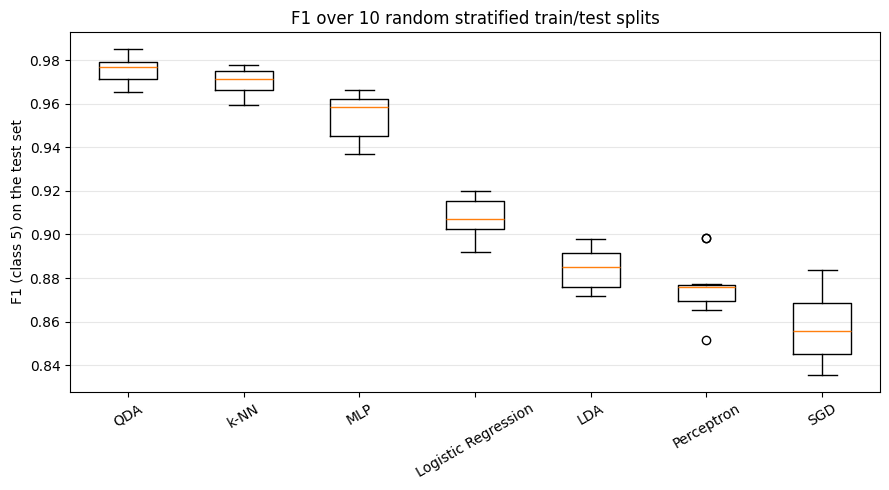

In [11]:
import matplotlib.pyplot as plt

ordine = medie.sort_values("f1", ascending=False).index
plt.figure(figsize=(9, 5))
plt.boxplot([tutti.loc[tutti["modello"] == m, "f1"] for m in ordine])
plt.xticks(range(1, len(ordine) + 1), ordine, rotation=30)
plt.ylabel("F1 (class 5) on the test set")
plt.title("F1 over 10 random stratified train/test splits")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("f1_boxplot.png", dpi=150)
plt.show()

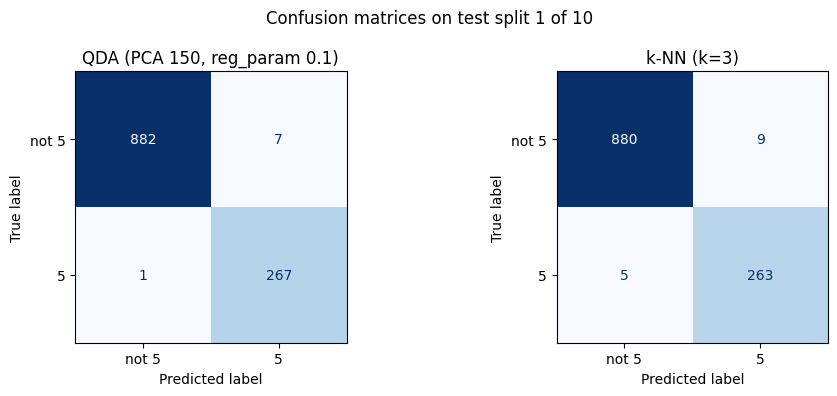

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

# Prendo il primo dei 10 split, lo stesso usato nella valutazione
divisioni = StratifiedShuffleSplit(n_splits=10, test_size=0.3, random_state=42)
idx_train, idx_test = next(divisioni.split(X, y))

# I parametri scelti più spesso dal tuning
modelli_finali = {
    "QDA (PCA 150, reg_param 0.1)": make_pipeline(PCA(n_components=150, random_state=0),
                                                  QuadraticDiscriminantAnalysis(reg_param=0.1)),
    "k-NN (k=3)": KNeighborsClassifier(n_neighbors=3),
}

fig, assi = plt.subplots(1, 2, figsize=(10, 4))
for asse, (nome, modello) in zip(assi, modelli_finali.items()):
    modello.fit(X[idx_train], y[idx_train])
    ConfusionMatrixDisplay.from_estimator(
        modello, X[idx_test], y[idx_test],
        display_labels=["not 5", "5"], cmap="Blues", colorbar=False, ax=asse)
    asse.set_title(nome)
plt.suptitle("Confusion matrices on test split 1 of 10")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()